# CIFAR-10 ResNet <5M — Kaggle runner
**Setup (right sidebar):** Accelerator → **GPU T4 x2** (or P100) · Internet → **On** · Input → the competition is attached
automatically when you create the notebook from the competition page ("Code" tab → "New Notebook").
Also upload `cifar10-resnet-5m.zip` as a **Dataset** (Input → "Upload" → name it `cifar10-resnet-5m-code`).

Run with **Save Version → Save & Run All (Commit)** so it keeps training for up to 12 h with the browser closed.
Outputs (checkpoints, `submission.csv`) land in `/kaggle/working` and persist with the saved version.

In [5]:
import os, glob, shutil
!nvidia-smi -L
COMP = glob.glob('/kaggle/input/**/cifar-10-res-net-architecture-challenge-dl', recursive=True)[0]
print(COMP, sorted(os.listdir(COMP)))
!rm -rf /kaggle/working/cifar10-resnet-5m
zips = glob.glob('/kaggle/input/**/cifar10-resnet-5m*.zip', recursive=True)
srcs = glob.glob('/kaggle/input/**/train.py', recursive=True)
if zips:
    !unzip -qo "{zips[0]}" -d /kaggle/working/
elif srcs:
    shutil.copytree(os.path.dirname(srcs[0]), '/kaggle/working/cifar10-resnet-5m')
else:
    raise FileNotFoundError('Code not found: Input → Add Input → Your Datasets → cifar10-resnet-5m-code')
%cd /kaggle/working/cifar10-resnet-5m
!rm -rf data checkpoints && mkdir -p data checkpoints
for name in ['train_images', 'test_images', 'train_labels.csv', 'test.csv']:
    os.symlink(f'{COMP}/{name}', f'data/{name}')
for p in glob.glob('/kaggle/input/**/checkpoints/*/last.pt', recursive=True):
    run = os.path.basename(os.path.dirname(p))
    shutil.copytree(os.path.dirname(p), f'checkpoints/{run}', dirs_exist_ok=True); print('restored', run)
!ls
print('train:', len(os.listdir('data/train_images')), 'test:', len(os.listdir('data/test_images')))

GPU 0: Tesla T4 (UUID: GPU-1137e6c3-88a8-d110-f30c-39e9f8d7d3dc)
GPU 1: Tesla T4 (UUID: GPU-700911a2-7d43-ac22-083f-51a4d14e531f)
/kaggle/input/competitions/cifar-10-res-net-architecture-challenge-dl ['sample_submission.csv', 'test.csv', 'test_images', 'train_images', 'train_labels.csv']
/kaggle/working/cifar10-resnet-5m
checkpoints  data.py  notebooks        predict.py  requirements.txt  train.py
data	     models   plot_results.py  README.md   run_hpc.sbatch
train: 50000 test: 2000


In [ ]:
!ls /kaggle/input; echo; find /kaggle/input -maxdepth 2 | head -20

### Train (T4 ≈ 55 s/epoch → 200 epochs ≈ 3 h; P100 ≈ 35 s/epoch)

In [7]:
RUN = 'checkpoints/resnet_se_343_s0'
!python train.py --model resnet_se_343 --epochs 200 --batch_size 128 --lr 0.1 \
    --train_csv data/train_labels.csv --train_dir data/train_images \
    --workers 4 --out {RUN} --resume {RUN}/last.pt

Model: resnet_se_343   trainable parameters: 4,988,274
Training on competition images: 50000 from data/train_images
100%|████████████████████████████████████████| 170M/170M [00:13<00:00, 12.7MB/s]
[  1/200] lr 0.0201 | train 2.022/28.88% | test 1.390/49.25% | ema 10.04% | val   nan% | 89s
[  2/200] lr 0.0401 | train 1.787/42.19% | test 1.162/60.30% | ema 12.55% | val   nan% | 37s
[  3/200] lr 0.0601 | train 1.664/48.67% | test 1.281/58.96% | ema 14.95% | val   nan% | 36s
[  4/200] lr 0.0801 | train 1.582/52.82% | test 1.043/66.95% | ema 24.01% | val   nan% | 36s
[  5/200] lr 0.1000 | train 1.538/55.51% | test 1.117/62.18% | ema 43.81% | val   nan% | 35s
[  6/200] lr 0.1000 | train 1.497/57.25% | test 0.892/70.50% | ema 64.80% | val   nan% | 36s
[  7/200] lr 0.1000 | train 1.446/59.45% | test 0.720/77.64% | ema 75.47% | val   nan% | 36s
[  8/200] lr 0.0999 | train 1.423/60.72% | test 0.659/79.30% | ema 80.54% | val   nan% | 36s
[  9/200] lr 0.0999 | train 1.415/61.02% | test 0.652/79.96

### Results, plots, submission

{
  "model": "resnet_se_343",
  "n_params": 4988274,
  "test_acc": 97.0,
  "test_acc_tta": 97.2
}saved figures/curves.png


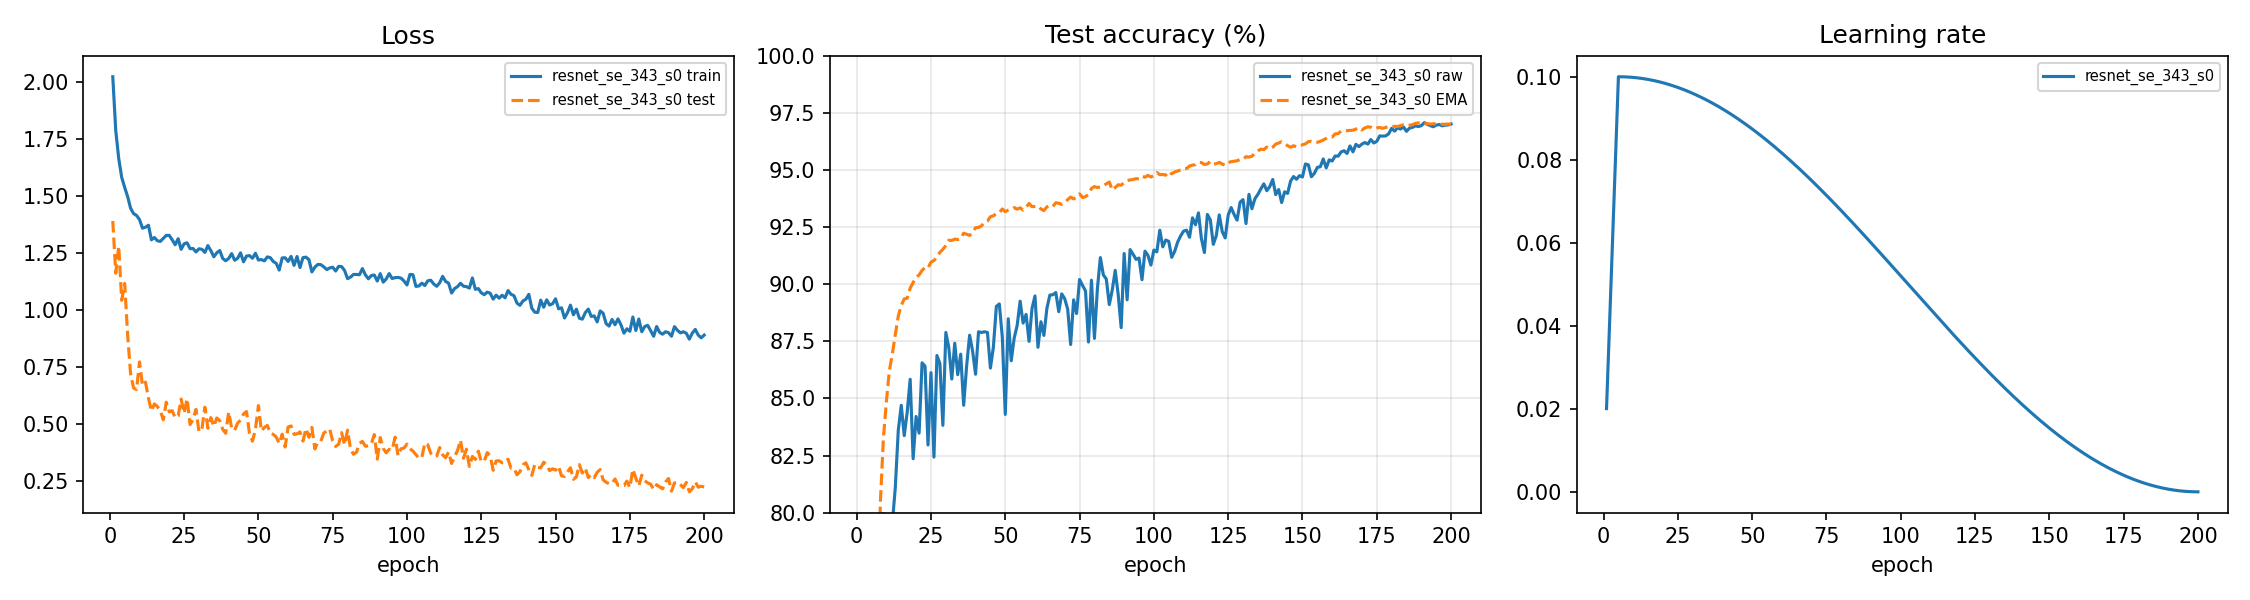

Loaded checkpoints/resnet_se_343_s0/best.pt: resnet_se_343, 4,988,274 params, weights=EMA
Wrote 2000 predictions to /kaggle/working/submission.csv
id,label
0,6
1,3


In [8]:
!cat {RUN}/final.json
!python plot_results.py {RUN} --out figures/curves.png
from IPython.display import Image; display(Image('figures/curves.png'))
!python predict.py --ckpts {RUN}/best.pt --test_csv data/test.csv --test_dir data/test_images --out /kaggle/working/submission.csv
!head -3 /kaggle/working/submission.csv
# keep the working dir small so the version saves quickly: drop the optimizer-laden last.pt copy of data symlinks
!rm -rf data

After the version finishes: open it → **Output** tab → `submission.csv` → **Submit to Competition**.
To continue training in a new version, add this notebook's own output as an Input (Input → "Your Work") so `last.pt` is restored.